<a href="https://colab.research.google.com/github/ai-abooser/useful_programs/blob/main/pages/solutions/02_sol_colab/colab_intro.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Colab Intro


## Prezentacja możliwości Colaba

---

### 2 + 2, 120 miejsc po przecinku

---



In [ ]:
import decimal

decimal.getcontext().prec = 130

wynik = decimal.Decimal("2") + decimal.Decimal("2")
print(f"{wynik:.120f}")

4.000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000


### pi razy pi do **120 miejsc po przecinku**

In [ ]:
import decimal

# Ustawiamy precyzję na ponad 120 miejsc, aby wynik był dokładny
decimal.getcontext().prec = 130

# Pobieramy dokładną wartość pi z modułu decimal z odpowiednio dużą dokładnością
pi = decimal.Decimal("3.141592653589793238462643383279502884197169399375105820974944592307816406286208998628034825342117067982148086513282306647")

# Obliczamy pi do potęgi pi
pi_pow_pi = pi ** pi

# Wyświetlamy z formatowaniem do 120 miejsc po przecinku
print(f"{pi_pow_pi:.120f}")

36.462159607207911770990826022692123666365508402228818738709335922934074368881699904620079875706774854368146883436700705420


### suma kwadratów liczb od 1 do 100

In [ ]:
import decimal

# Ustawiamy precyzję na co najmniej 30 miejsc, aby wynik formatowania do 20 był dokładny
decimal.getcontext().prec = 30

# Obliczamy sumę kwadratów liczb od 1 do 100 przy użyciu typów Decimal
suma_kwadratow = sum(decimal.Decimal(i)**2 for i in range(1, 101))

# Wyświetlamy wynik z dokładnością do 20 miejsc po przecinku
print(f"{suma_kwadratow:.20f}")

338350.00000000000000000000


In [ ]:
import decimal

# Ustawiamy precyzję
decimal.getcontext().prec = 30
suma_kwadratow = sum(decimal.Decimal(i)**2 for i in range(1, 101))
wynik_str = f"{suma_kwadratow:.20f}"

# Zapisujemy wynik do pliku colab_wynik.txt
with open("colab_wynik.txt", "w") as f:
    f.write(wynik_str)

print("Wynik został pomyślnie zapisany do pliku colab_wynik.txt!")

Wynik został pomyślnie zapisany do pliku colab_wynik.txt!


### komórka kodu tworząca wykres y=k^2 dla k o wartościach od 1 do 20


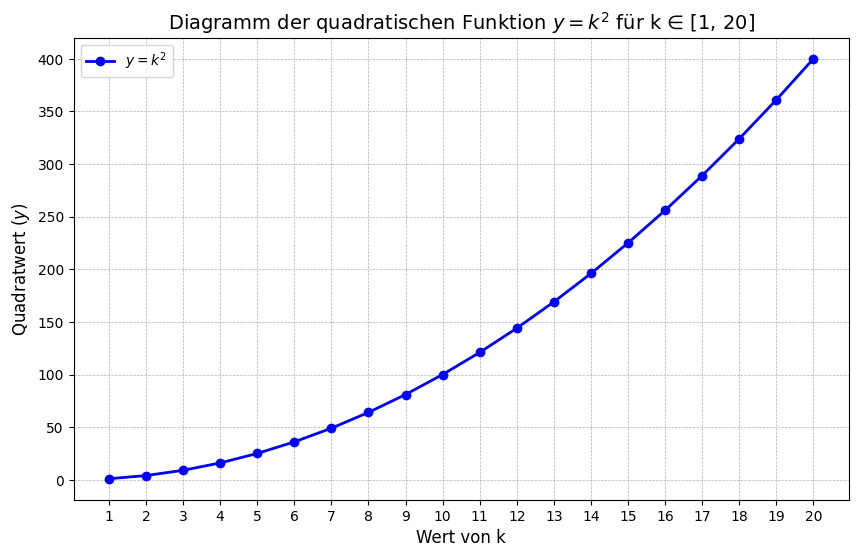

In [ ]:
import matplotlib.pyplot as plt

# Daten für das Diagramm definieren
k = list(range(1, 21))
y = [val**2 for val in k]

# Diagramm erstellen
plt.figure(figsize=(10, 6))
plt.plot(k, y, marker='o', color='b', linestyle='-', linewidth=2, label='$y = k^2$')

# Titel und Achsenbeschriftungen auf Deutsch (mit Unicode-Symbol, um Backslash-Warnungen zu vermeiden)
plt.title('Diagramm der quadratischen Funktion $y = k^2$ für k ∈ [1, 20]', fontsize=14)
plt.xlabel('Wert von k', fontsize=12)
plt.ylabel('Quadratwert ($y$)', fontsize=12)

# Gitter und Legende hinzufügen
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.legend(loc='upper left')
plt.xticks(k)

# Diagramm anzeigen
plt.show()

In [ ]:
import matplotlib.pyplot as plt

# Ponowne zdefiniowanie danych i wyrysowanie wykresu w celu jego zapisu
k = list(range(1, 21))
y = [val**2 for val in k]

plt.figure(figsize=(10, 6))
plt.plot(k, y, marker='o', color='b', linestyle='-', linewidth=2, label='$y = k^2$')

# Tytuł i etykiety po niemiecku
plt.title('Diagramm der quadratischen Funktion $y = k^2$ für k ∈ [1, 20]', fontsize=14)
plt.xlabel('Wert von k', fontsize=12)
plt.ylabel('Quadratwert ($y$)', fontsize=12)
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.legend(loc='upper left')
plt.xticks(k)

# Zapisanie wykresu do pliku wykres.png
plt.savefig('wykres.png', dpi=300, bbox_inches='tight')
plt.close()

print("Wykres został pomyślnie zapisany jako 'wykres.png'!")

Wykres został pomyślnie zapisany jako 'wykres.png'!


### Podwójne wahadło (Teoria Chaosu) - animacja MP4:

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML
import base64

# Parametry fizyczne układu
g = 9.81
m1, m2 = 1.0, 1.0  # masy wahadeł (kg)
L1, L2 = 1.0, 1.0  # długości nici (m)

# Warunki początkowe (kąty w radianach, prędkości kątowe)
theta1_0 = np.radians(90.0)   # pierwsze wahadło odchylone do poziomu
theta2_0 = np.radians(90.0)   # drugie wahadło również
omega1_0 = 0.0
omega2_0 = 0.0

# Parametry czasu symulacji
t_max = 15.0
fps = 30
dt = 1.0 / fps
t = np.arange(0.0, t_max, dt)

# Funkcja zwracająca pochodne (równania ruchu wyprowadzone z mechaniki lagranżowskiej)
def equations(state):
    th1, w1, th2, w2 = state
    delta = th1 - th2

    # Mianownik wspólny dla obu przyspieszeń kątowych
    den1 = L1 * (2*m1 + m2 - m2*np.cos(2*th1 - 2*th2))
    den2 = L2 * (2*m1 + m2 - m2*np.cos(2*th1 - 2*th2))

    # Przyspieszenia kątowe
    alpha1 = (-g*(2*m1 + m2)*np.sin(th1) - m2*g*np.sin(th1 - 2*th2) - 2*np.sin(delta)*m2*(w2**2*L2 + w1**2*L1*np.cos(delta))) / den1
    alpha2 = (2*np.sin(delta)*(w1**2*L1*(m1 + m2) + g*(m1 + m2)*np.cos(th1) + w2**2*L2*m2*np.cos(delta))) / den2

    return np.array([w1, alpha1, w2, alpha2])

# Solwer RK4 (Runge-Kutta 4. rzędu) dla stabilności numerycznej
state = np.array([theta1_0, omega1_0, theta2_0, omega2_0])
history = np.zeros((len(t), 4))
history[0] = state

for i in range(1, len(t)):
    y = history[i-1]
    k1 = equations(y)
    k2 = equations(y + 0.5 * dt * k1)
    k3 = equations(y + 0.5 * dt * k2)
    k4 = equations(y + dt * k3)
    history[i] = y + (dt / 6.0) * (k1 + 2*k2 + 2*k3 + k4)

# Wyznaczenie współrzędnych kartezjańskich mas
th1_sol, _, th2_sol, _ = history.T
x1 = L1 * np.sin(th1_sol)
y1 = -L1 * np.cos(th1_sol)
x2 = x1 + L2 * np.sin(th2_sol)
y2 = y1 - L2 * np.cos(th2_sol)

# Konfiguracja wykresu do animacji
fig, ax = plt.subplots(figsize=(6, 6))
ax.set_xlim(-2.2, 2.2)
ax.set_ylim(-2.2, 2.2)
ax.set_aspect('equal')
ax.grid(True, linestyle='--', alpha=0.5)
ax.set_title("Chaotyczne Podwójne Wahadło", fontsize=14)
ax.set_xlabel("X [m]")
ax.set_ylabel("Y [m]")

line, = ax.plot([], [], 'o-', lw=3, color='#1f77b4', markersize=8)
trace, = ax.plot([], [], '-', color='#ff7f0e', alpha=0.6, lw=1.5)

def init():
    line.set_data([], [])
    trace.set_data([], [])
    return line, trace

def animate(i):
    # Punkty przegubów i mas
    thisx = [0, x1[i], x2[i]]
    thisy = [0, y1[i], y2[i]]
    line.set_data(thisx, thisy)

    # Rysowanie śladu ruchu dolnej masy
    trace_length = 150
    start = max(0, i - trace_length)
    trace.set_data(x2[start:i], y2[start:i])
    return line, trace

# Tworzenie animacji
ani = animation.FuncAnimation(fig, animate, init_func=init, frames=len(t), interval=1000/fps, blit=True)

# Zapis do pliku video.mp4 (zamieniamy poprzedni plik)
writer = animation.FFMpegWriter(fps=fps, metadata=dict(artist='Colab Chaos'), bitrate=2000)
ani.save('video.mp4', writer=writer)
plt.close()

# Wyświetlenie gotowego wideo
video_file = open('video.mp4', 'rb').read()
video_base64 = base64.b64encode(video_file).decode('ascii')
video_html = f'''
<video width="500" height="500" controls autoplay loop>
  <source src="data:video/mp4;base64,{video_base64}" type="video/mp4">
  Your browser does not support the video tag.
</video>
'''
HTML(video_html)

In [ ]:
import imageio

# Nazwy plików wejściowych i wyjściowych
input_mp4 = "video.mp4"
output_gif = "video.gif"

try:
    # Odczytujemy klatki z pliku MP4 i zapisujemy je jako GIF
    print(f"Rozpoczynam konwersję pliku '{input_mp4}' do formatu GIF...")
    reader = imageio.get_reader(input_mp4)
    fps = reader.get_meta_data().get('fps', 30)

    writer = imageio.get_writer(output_gif, fps=fps)
    for frame in reader:
        writer.append_data(frame)
    writer.close()

    print(f"Sukces! Animowany plik został zapisany pod nazwą: '{output_gif}' w Twoim głównym katalogu roboczym.")
except Exception as e:
    print(f"Wystąpił błąd podczas konwersji: {e}")

Rozpoczynam konwersję pliku 'video.mp4' do formatu GIF...
Sukces! Animowany plik został zapisany pod nazwą: 'video.gif' w Twoim głównym katalogu roboczym.


### Zmodyfikowana krzywa parametryczna


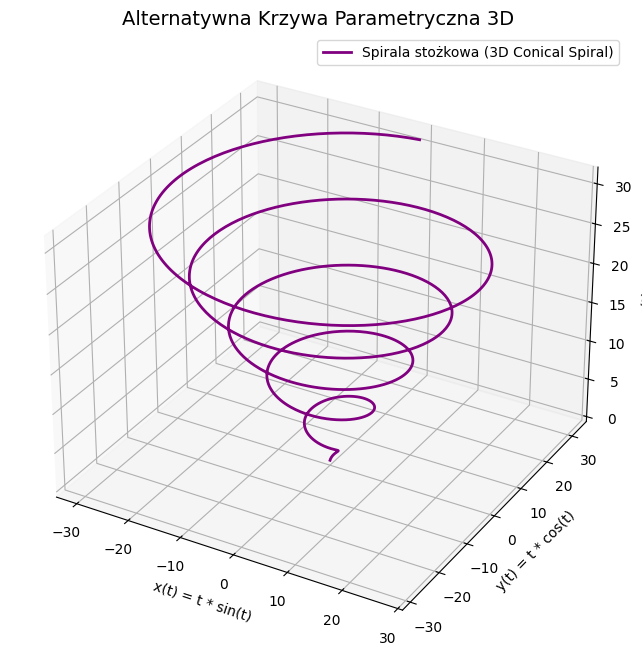

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Parametric equations for a 3D conical spiral
t = np.linspace(0, 10 * np.pi, 1000)
x = t * np.sin(t)
y = t * np.cos(t)
z = t

# 3D Plot
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')
ax.plot(x, y, z, label="Spirala stożkowa (3D Conical Spiral)", color='purple', linewidth=2)
ax.set_title("Alternatywna Krzywa Parametryczna 3D", fontsize=14)
ax.set_xlabel("x(t) = t * sin(t)")
ax.set_ylabel("y(t) = t * cos(t)")
ax.set_zlabel("z(t) = t")
ax.legend()

# Zapis do pliku graficznego
plt.savefig('parametric_curve.png', dpi=300, bbox_inches='tight')
plt.show()